In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import io
import time

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from pathlib import Path

In [2]:
df = pd.read_csv("../data/processed/telco_clean.csv")

y = df["Churn"]
X = df.drop(columns=["Churn"])

print("X:", X.shape)
print("y:", y.shape)
print(30 * "--")
print(y.value_counts(normalize=True).round(3))

X: (7043, 19)
y: (7043,)
------------------------------------------------------------
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,         
    stratify=y_temp,        
    random_state=42,
)

for name, X_part, y_part in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    print(f"{name:10s} X: {X_part.shape}  y: {y_part.shape}  churn: {y_part.mean():.3f}")

train      X: (4225, 19)  y: (4225,)  churn: 0.265
validation X: (1409, 19)  y: (1409,)  churn: 0.265
test       X: (1409, 19)  y: (1409,)  churn: 0.265


In [4]:
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print(f"Kolumny tekstowe ({len(cat_cols)}):")
print(cat_cols)
print(30 * "--")
print(f"Kolumny liczbowe ({len(num_cols)}):")
print(num_cols)

Kolumny tekstowe (15):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
------------------------------------------------------------
Kolumny liczbowe (4):
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [5]:
scale_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
flag_cols = ["SeniorCitizen"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), scale_cols),
        ("flag", "passthrough", flag_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)  
X_val_prep = preprocessor.transform(X_val)           

print("train:", X_train_prep.shape)
print("validation:", X_val_prep.shape)

names = preprocessor.get_feature_names_out()
print(len(names))
print(names[:4])
print(names[-5:])

train: (4225, 45)
validation: (1409, 45)
45
['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes']
['cat__PaymentMethod_Mailed check' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'flag__SeniorCitizen']


## Model bazowy

Musimy mieć co przebić. DummyClassifier to najgłupszy możliwy model: zawsze odpowiada „klient nie odejdzie”.

Wchodzi pipeline, żeby nie było data leakage. W każdym Pipeline używamy kopii preprocessora (`clone`), bo Pipeline nie kopiuje obiektów, które dostaje, i kolejne `fit` nadpisywałyby ten sam preprocessor.

In [6]:
dummy = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", DummyClassifier(strategy="most_frequent")),  
])

dummy.fit(X_train, y_train)         
y_val_pred = dummy.predict(X_val)    

print("accuracy :", round(accuracy_score(y_val, y_val_pred), 3))
print("recall   :", round(recall_score(y_val, y_val_pred), 3))
print("precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 3))
print("F1       :", round(f1_score(y_val, y_val_pred, zero_division=0), 3))
print(30 * "--")
print("Przewidziane klasy:", pd.Series(y_val_pred).value_counts().to_dict())

accuracy : 0.735
recall   : 0.0
precision: 0.0
F1       : 0.0
------------------------------------------------------------
Przewidziane klasy: {0: 1409}


Accuracy $73,5\%$ wygląda przyzwoicie, ale model nie zrobił nic. To po prostu odsetek klientów, którzy zostali.
Recall $0\%$. Z klientów, którzy odeszli, nie wyłapał ani jednego.

Tu wychodzi, dlaczego accuracy nie ma sensu dla takiego modelu. 

In [7]:
logreg = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg.fit(X_train, y_train)

y_val_pred = logreg.predict(X_val)                 
y_val_proba = logreg.predict_proba(X_val)[:, 1]    

print("accuracy :", round(accuracy_score(y_val, y_val_pred), 3))
print("recall   :", round(recall_score(y_val, y_val_pred), 3))
print("precision:", round(precision_score(y_val, y_val_pred), 3))
print("F1       :", round(f1_score(y_val, y_val_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_val, y_val_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, y_val_proba), 3))
print(30 * "--")
print("Macierz pomyłek (wiersze = prawda, kolumny = predykcja):")
print(confusion_matrix(y_val, y_val_pred))

accuracy : 0.803
recall   : 0.535
precision: 0.658
F1       : 0.59
ROC-AUC  : 0.836
PR-AUC   : 0.642
------------------------------------------------------------
Macierz pomyłek (wiersze = prawda, kolumny = predykcja):
[[931 104]
 [174 200]]


Sprawdzam poprawność:

naprawdę został (0): 931 (trafnie) ; 104 (fałszywy alarm)

naprawdę odszedł (1): 174 (przeoczony) ; 200 (trafnie wyłapany)

931 + 104 = 1035 klientów, którzy zostali,
174 + 200 = 374 klientów, którzy odeszli.

Razem 1035 + 374 = 1409, czyli cała validation. Odsetek odejść to 374 / 1409 = 26,5%, zgadza się z EDA.

## Podnosimy recall

Baseline wyłapuje 53,5% odchodzących. Podnieśmy wykrywalność kosztem fałszywych alarmów. Takie alarmy są tańsze niż przeoczenie faktycznego odejścia.

Wprowadzenie *class_weight="balanced"*.

In [8]:
logreg_bal = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

logreg_bal.fit(X_train, y_train)

y_val_pred = logreg_bal.predict(X_val)
y_val_proba = logreg_bal.predict_proba(X_val)[:, 1]

print("accuracy :", round(accuracy_score(y_val, y_val_pred), 3))
print("recall   :", round(recall_score(y_val, y_val_pred), 3))
print("precision:", round(precision_score(y_val, y_val_pred), 3))
print("F1       :", round(f1_score(y_val, y_val_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_val, y_val_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, y_val_proba), 3))
print(30 * "--")
print(confusion_matrix(y_val, y_val_pred))

accuracy : 0.747
recall   : 0.789
precision: 0.515
F1       : 0.623
ROC-AUC  : 0.836
PR-AUC   : 0.642
------------------------------------------------------------
[[757 278]
 [ 79 295]]


Recall	wzrósł z 0,535 na 0,789, ale fałszywe alarmy wzrosły z 104 na 278. ROC-AUC i PR-AUC bez zmian. OK

## Próg decyzyjny

Zmiana progu daje ten sam efekt co `class_weight`: przesuwa kompromis między recall a precision. Poniżej tabela dla modelu bez `class_weight`.

In [9]:
proba = logreg.predict_proba(X_val)[:, 1]    
rows = []
for thr in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (proba >= thr).astype(int)       
    rows.append({
        "próg": thr,
        "recall": recall_score(y_val, pred),
        "precision": precision_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "alarmy": int(pred.sum()),
        "FN (przeoczeni)": int(((pred == 0) & (y_val == 1)).sum()),
        "FP (fałszywe)": int(((pred == 1) & (y_val == 0)).sum()),
    })

threshold_table = pd.DataFrame(rows).round(3)
threshold_table

,próg,recall,precision,F1,alarmy,FN (przeoczeni),FP (fałszywe)
0,0.10,0.922,0.394,0.552,875,29,530
1,0.15,0.888,0.428,0.578,775,42,443
2,0.20,0.834,0.465,0.597,671,62,359
3,0.25,0.802,0.507,0.621,592,74,292
4,0.30,0.751,0.537,0.627,523,93,242
5,0.35,0.706,0.567,0.629,466,110,202
6,0.40,0.644,0.595,0.619,405,133,164
7,0.45,0.591,0.633,0.611,349,153,128
8,0.50,0.535,0.658,0.590,304,174,104


In [10]:
best_row = threshold_table.loc[threshold_table['F1'].idxmax()]
print("\n" + "="*50)
print(f"Najlepszy próg wg F1-score: {best_row['próg']}")
print(f"Precision: {best_row['precision']} | Recall: {best_row['recall']} | F1: {best_row['F1']}")
print(f"Liczba alarmów (wskazanych do retencji): {best_row['alarmy']}")
print(f"Przeoczeni klienci (FN): {best_row['FN (przeoczeni)']}")
print(f"Fałszywe alarmy (FP): {best_row['FP (fałszywe)']}")
print("="*50)


Najlepszy próg wg F1-score: 0.35
Precision: 0.567 | Recall: 0.706 | F1: 0.629
Liczba alarmów (wskazanych do retencji): 466.0
Przeoczeni klienci (FN): 110.0
Fałszywe alarmy (FP): 202.0


Najwyższe F1 daje próg 0,35, ale F1 jest niemal płaskie w zakresie 0,20–0,45 i nie uwzględnia kosztów. Próg 0,35 jest tu tylko roboczy. Ostateczny próg wybieramy w sekcji „Wybór progu na podstawie kosztów” (wynik: 0,38).

## Nowe cechy

Sprawdzamy cechy `n_protect`, `fiber_no_support`, `ServiceCount` i `ChargePerService`, dodając je pojedynczo do regresji logistycznej. Porównujemy PR-AUC na validation (roboczy próg 0,35 służy tylko do podglądu recall i precision).

In [11]:
protect_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def add_features(data):
    """Dodaje nowe cechy. Działa wierszami, więc nie 'uczy się' niczego z danych (brak data leakage)."""
    d = data.copy()
    d["n_protect"] = d[protect_cols].eq("Yes").sum(axis=1)                       # 0-4
    d["ServiceCount"] = (
        d[service_cols].eq("Yes").sum(axis=1)
        + d["InternetService"].isin(["DSL", "Fiber optic"]).astype(int)
    )                                                                              # 0-9
    d["ChargePerService"] = d["MonthlyCharges"] / (d["ServiceCount"] + 1)
    d["fiber_no_support"] = (
        (d["InternetService"] == "Fiber optic")
        & (d["OnlineSecurity"] != "Yes")
        & (d["TechSupport"] != "Yes")
    ).astype(int)
    return d


def make_model(extra_scale=(), extra_flag=()):
    """Pipeline: nowe cechy -> preprocessing -> regresja logistyczna."""
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), ["tenure", "MonthlyCharges", "TotalCharges", *extra_scale]),
        ("flag", "passthrough", ["SeniorCitizen", *extra_flag]),
    ])
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("prep", prep),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ])


variants = {
    "baseline (bez nowych cech)": make_model(),
    "+ n_protect": make_model(extra_scale=["n_protect"]),
    "+ fiber_no_support": make_model(extra_flag=["fiber_no_support"]),
    "+ ServiceCount": make_model(extra_scale=["ServiceCount"]),
    "+ ChargePerService": make_model(extra_scale=["ChargePerService"]),
    "+ n_protect + fiber_no_support": make_model(["n_protect"], ["fiber_no_support"]),
}

THRESHOLD = 0.35
rows = []
for name, model in variants.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    pred = (proba >= THRESHOLD).astype(int)
    rows.append({
        "wariant": name,
        "PR-AUC": average_precision_score(y_val, proba),
        "ROC-AUC": roc_auc_score(y_val, proba),
        f"recall@{THRESHOLD}": recall_score(y_val, pred),
        f"precision@{THRESHOLD}": precision_score(y_val, pred),
    })

pd.DataFrame(rows).round(3)

,wariant,PR-AUC,ROC-AUC,recall@0.35,precision@0.35
0,baseline (bez nowych cech),0.642,0.836,0.706,0.567
1,+ n_protect,0.642,0.836,0.706,0.567
2,+ fiber_no_support,0.642,0.836,0.698,0.565
3,+ ServiceCount,0.642,0.836,0.706,0.567
4,+ ChargePerService,0.642,0.836,0.706,0.567
5,+ n_protect + fiber_no_support,0.641,0.835,0.698,0.565


Żadna z cech nie poprawia modelu (PR-AUC 0,642 bez zmian), więc nie wchodzą do modelu.

## Porównanie modeli

5-krotna walidacja krzyżowa na zbiorze treningowym, te same foldy, metryka PR-AUC.

In [12]:
new_scale = ["n_protect", "ServiceCount"]
new_flag = ["fiber_no_support"]


def make_pipe(model, use_new_features):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), ["tenure", "MonthlyCharges", "TotalCharges"] + (new_scale if use_new_features else [])),
        ("flag", "passthrough", ["SeniorCitizen"] + (new_flag if use_new_features else [])),
    ])
    return Pipeline([("features", FunctionTransformer(add_features)), ("prep", prep), ("model", model)])


models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   

rows = []
for model_name, model in models.items():
    for use_new in [False, True]:
        scores = cross_validate(
            make_pipe(model, use_new), X_train, y_train,
            cv=cv, scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"},
        )
        rows.append({
            "model": model_name,
            "nowe cechy": "tak" if use_new else "nie",
            "PR-AUC (średnia)": scores["test_PR-AUC"].mean(),
            "PR-AUC (odch. std.)": scores["test_PR-AUC"].std(),
            "ROC-AUC (średnia)": scores["test_ROC-AUC"].mean(),
        })

cv_results = pd.DataFrame(rows).round(3)
cv_results

,model,nowe cechy,PR-AUC (średnia),PR-AUC (odch. std.),ROC-AUC (średnia)
0,LogisticRegression,nie,0.666,0.025,0.848
1,LogisticRegression,tak,0.666,0.025,0.848
2,RandomForest,nie,0.667,0.009,0.846
3,RandomForest,tak,0.667,0.010,0.846
4,HistGradientBoosting,nie,0.641,0.012,0.832
5,HistGradientBoosting,tak,0.639,0.010,0.828


Regresja logistyczna i Random Forest dają praktycznie ten sam wynik (PR-AUC 0,666 i 0,667 przy odchyleniu standardowym 0,01–0,025), a HistGradientBoosting wypada gorzej (0,641). Nowe cechy nie pomagają żadnemu modelowi. **Wybieramy regresję logistyczną jako model prostszy i łatwiejszy do wyjaśnienia.**

## Strojenie

Strojenie parametru regularyzacji `C` regresji logistycznej (GridSearchCV na zbiorze treningowym, metryka PR-AUC).

In [13]:
final_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

param_grid = {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}

grid = GridSearchCV(
    final_pipe, param_grid,
    scoring="average_precision",  
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),  
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Najlepsze parametry:", grid.best_params_)
print("Najlepsze PR-AUC (CV na train):", round(grid.best_score_, 3))
print(30 * "--")

results = (
    pd.DataFrame(grid.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
)
print(results.to_string(index=False))

best_model = grid.best_estimator_
proba_val = best_model.predict_proba(X_val)[:, 1]
print(30 * "--")
print("PR-AUC na validation:", round(average_precision_score(y_val, proba_val), 3))
print("ROC-AUC na validation:", round(roc_auc_score(y_val, proba_val), 3))

Najlepsze parametry: {'model__C': 10}
Najlepsze PR-AUC (CV na train): 0.668
------------------------------------------------------------
 param_model__C  mean_test_score  std_test_score
         10.000           0.6679          0.0244
         30.000           0.6676          0.0243
          3.000           0.6671          0.0246
          1.000           0.6665          0.0249
          0.300           0.6656          0.0246
          0.100           0.6644          0.0239
          0.030           0.6637          0.0221
          0.010           0.6635          0.0204
          0.003           0.6620          0.0189
------------------------------------------------------------
PR-AUC na validation: 0.643
ROC-AUC na validation: 0.837


Zmiana `C` w zakresie 0,003–30 zmienia PR-AUC tylko o 0,006 (0,662–0,668), więc zostawiamy domyślne `C=1`.

## Wybór progu na podstawie kosztów

Założenia (nie pochodzą z danych): koszt akcji retencyjnej 100 USD na klienta (kontakt i oferta, np. rabat w skali roku), wartość uratowanego klienta 780 USD (12 miesięcy × ok. 65 USD przychodu), skuteczność oferty 35%.

In [14]:
COST_CONTACT = 100     
VALUE_SAVED = 780      
SUCCESS_RATE = 0.35    

final_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
final_model.fit(X_train, y_train)
proba_val = final_model.predict_proba(X_val)[:, 1]


def profit_at(threshold, cost):
    """Oczekiwany zysk netto na validation dla danego progu i kosztu kontaktu."""
    pred = proba_val >= threshold
    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    return tp * (SUCCESS_RATE * VALUE_SAVED - cost) - fp * cost


rows = []
for thr in [0.25, 0.30, 0.35, 0.38, 0.40, 0.45, 0.50, 0.55]:
    pred = (proba_val >= thr).astype(int)
    tp = int(((pred == 1) & (y_val == 1)).sum())
    fp = int(((pred == 1) & (y_val == 0)).sum())
    fn = int(((pred == 0) & (y_val == 1)).sum())
    rows.append({
        "próg": thr, "alarmy": tp + fp, "TP": tp, "FP": fp, "FN": fn,
        "recall": tp / (tp + fn), "precision": tp / (tp + fp),
        "zysk netto [$]": profit_at(thr, COST_CONTACT),
    })
print(f"Koszt kontaktu: {COST_CONTACT} $, zysk z trafionego alarmu: {SUCCESS_RATE * VALUE_SAVED - COST_CONTACT:.0f} $")
print(pd.DataFrame(rows).round(3).to_string(index=False))


grid_thr = np.round(np.arange(0.01, 0.91, 0.01), 2)
BEST_THRESHOLD = grid_thr[int(np.argmax([profit_at(t, COST_CONTACT) for t in grid_thr]))]
print(30 * "--")
print("BEST_THRESHOLD =", BEST_THRESHOLD)

pred = (proba_val >= BEST_THRESHOLD).astype(int)
print("recall   :", round(recall_score(y_val, pred), 3))
print("precision:", round(precision_score(y_val, pred), 3))
print("F1       :", round(f1_score(y_val, pred), 3))
print("PR-AUC   :", round(average_precision_score(y_val, proba_val), 3))
print(confusion_matrix(y_val, pred))


sens = []
for cost in [10, 50, 100, 150, 200]:
    profits = [profit_at(t, cost) for t in grid_thr]
    i = int(np.argmax(profits))
    all_contact = (y_val == 1).sum() * (SUCCESS_RATE * VALUE_SAVED - cost) - (y_val == 0).sum() * cost
    sens.append({
        "koszt kontaktu [$]": cost,
        "najlepszy próg": grid_thr[i],
        "zysk przy najlepszym progu [$]": round(profits[i]),
        "zysk: kontakt ze wszystkimi [$]": round(all_contact),
    })
print(30 * "--")
print(pd.DataFrame(sens).to_string(index=False))

Koszt kontaktu: 100 $, zysk z trafionego alarmu: 173 $
 próg  alarmy  TP  FP  FN  recall  precision  zysk netto [$]
 0.25     592 300 292  74   0.802      0.507         22700.0
 0.30     523 281 242  93   0.751      0.537         24413.0
 0.35     466 264 202 110   0.706      0.567         25472.0
 0.38     426 252 174 122   0.674      0.592         26196.0
 0.40     405 241 164 133   0.644      0.595         25293.0
 0.45     349 221 128 153   0.591      0.633         25433.0
 0.50     304 200 104 174   0.535      0.658         24200.0
 0.55     263 181  82 193   0.484      0.688         23113.0
------------------------------------------------------------
BEST_THRESHOLD = 0.38
recall   : 0.674
precision: 0.592
F1       : 0.63
PR-AUC   : 0.642
[[861 174]
 [122 252]]
------------------------------------------------------------
 koszt kontaktu [$]  najlepszy próg  zysk przy najlepszym progu [$]  zysk: kontakt ze wszystkimi [$]
                 10            0.04                          

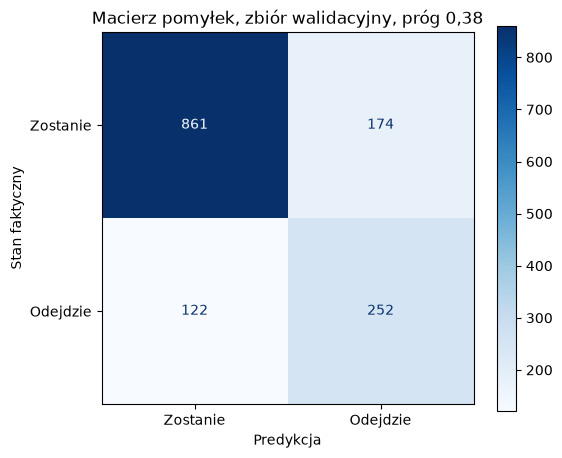

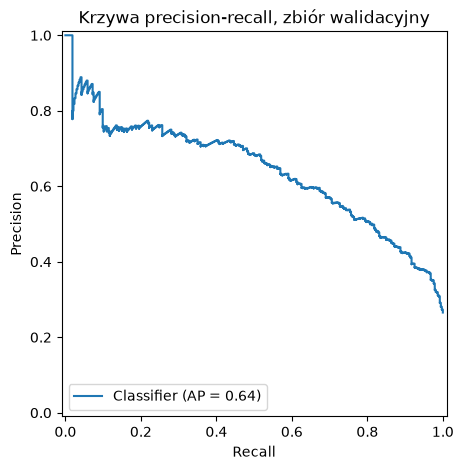

In [15]:
os.makedirs("../reports/figures", exist_ok=True)

y_pred_val = (proba_val >= float(BEST_THRESHOLD)).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_val, display_labels=["Zostanie", "Odejdzie"], cmap="Blues", ax=ax)
ax.set_title("Macierz pomyłek, zbiór walidacyjny, próg 0,38")
ax.set_xlabel("Predykcja"); ax.set_ylabel("Stan faktyczny")
fig.savefig("../reports/figures/confusion_matrix_val.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_val, proba_val, ax=ax)
ax.set_title("Krzywa precision-recall, zbiór walidacyjny")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
fig.savefig("../reports/figures/pr_curve_val.png", dpi=200, bbox_inches="tight")
plt.show()

Maksymalny zysk daje próg 0,38 (recall 0,674, precision 0,592). Krzywa zysku jest płaska w zakresie progów 0,30–0,50. Próg zależy od kosztu kontaktu: od 0,04 przy 10 USD do 0,75 przy 200 USD, a przy bardzo tanim kontakcie opłaca się kontaktować prawie ze wszystkimi.

## Ocena na zbiorze testowym (jednorazowa)

Finalny model uczymy na train + validation i oceniamy raz na zbiorze testowym przy progu z poprzedniej sekcji. Po tej ocenie nie wracamy do strojenia.

In [16]:
THRESHOLD = 0.38         


test_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
test_model.fit(X_temp, y_temp)


proba_test = test_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= THRESHOLD).astype(int)

tp = int(((pred_test == 1) & (y_test == 1)).sum())
fp = int(((pred_test == 1) & (y_test == 0)).sum())
fn = int(((pred_test == 0) & (y_test == 1)).sum())
tn = int(((pred_test == 0) & (y_test == 0)).sum())

print("recall   :", round(recall_score(y_test, pred_test), 3))
print("precision:", round(precision_score(y_test, pred_test), 3))
print("F1       :", round(f1_score(y_test, pred_test), 3))
print("PR-AUC   :", round(average_precision_score(y_test, proba_test), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, proba_test), 3))
print(30 * "--")
print("Macierz pomyłek (wiersze = prawda, kolumny = predykcja):")
print(confusion_matrix(y_test, pred_test))

gain_per_tp = SUCCESS_RATE * VALUE_SAVED - COST_CONTACT
print(30 * "--")
print(f"Oczekiwany zysk netto na teście (koszt {COST_CONTACT} $): {tp * gain_per_tp - fp * COST_CONTACT:.0f} $")


rng = np.random.default_rng(42)
y_arr, p_arr = y_test.to_numpy(), pred_test
rec, prec = [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yy, pp = y_arr[idx], p_arr[idx]
    rec.append(recall_score(yy, pp))
    prec.append(precision_score(yy, pp))
print(30 * "--")
print("recall    95% przedział:", np.percentile(rec, [2.5, 97.5]).round(3))
print("precision 95% przedział:", np.percentile(prec, [2.5, 97.5]).round(3))

recall   : 0.687
precision: 0.56
F1       : 0.617
PR-AUC   : 0.633
ROC-AUC  : 0.842
------------------------------------------------------------
Macierz pomyłek (wiersze = prawda, kolumny = predykcja):
[[833 202]
 [117 257]]
------------------------------------------------------------
Oczekiwany zysk netto na teście (koszt 100 $): 24261 $
------------------------------------------------------------
recall    95% przedział: [0.638 0.732]
precision 95% przedział: [0.513 0.604]


Wynik na teście (recall 0,687, precision 0,560, PR-AUC 0,633) jest zbliżony do walidacyjnego, a różnice mieszczą się w przedziałach niepewności.

## Interpretacja modelu

Współczynniki całego modelu oraz wyjaśnienie pojedynczych klientów (wkład cechy = współczynnik × odchylenie cechy od średniej).

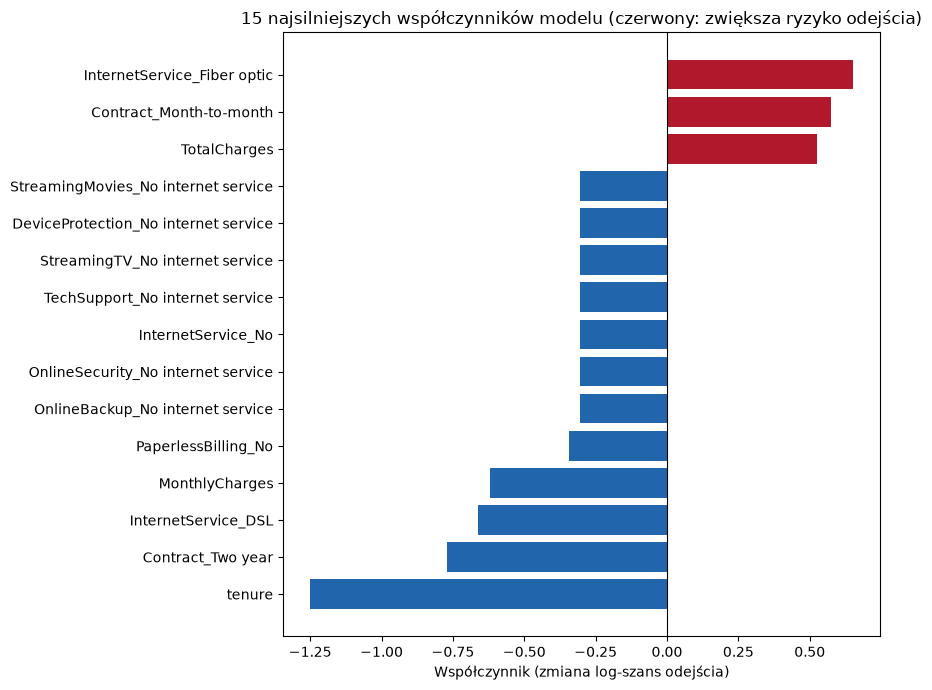

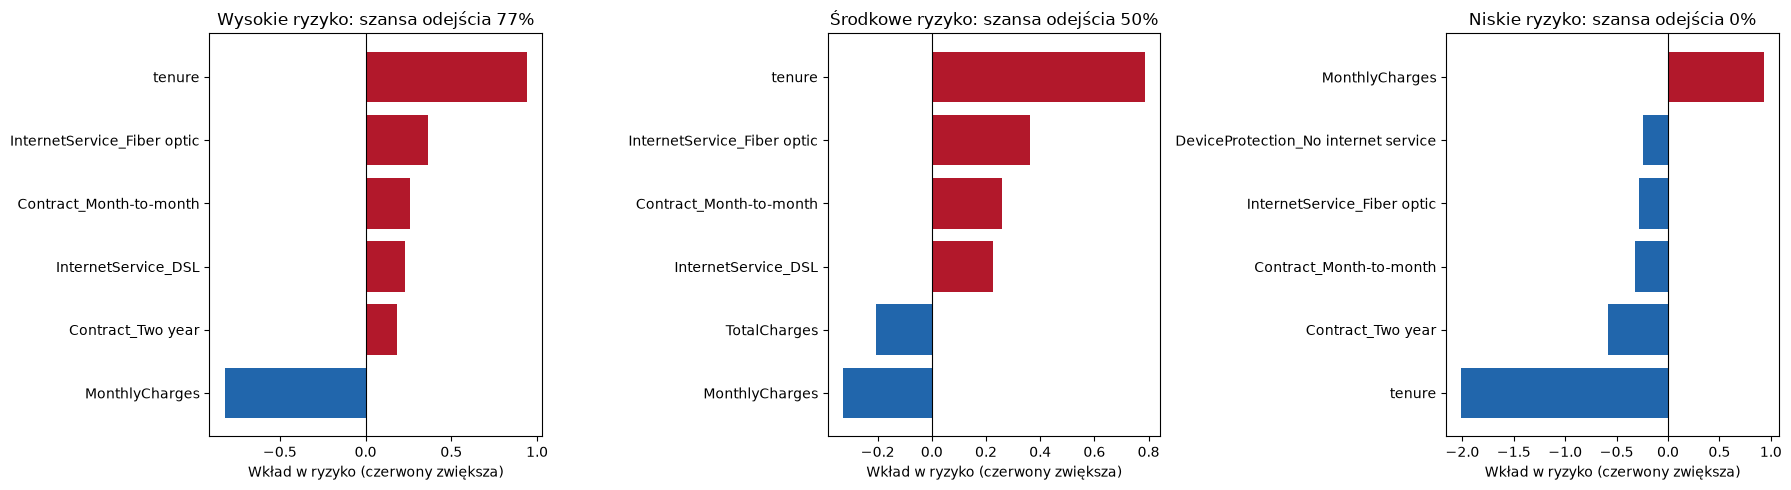

=== Wysokie ryzyko (klient nr 100, szansa odejścia 77%) ===
Contract             Month-to-month
tenure                           14
InternetService         Fiber optic
OnlineSecurity                   No
TechSupport                      No
PaymentMethod      Electronic check
MonthlyCharges               104.85

=== Środkowe ryzyko (klient nr 1150, szansa odejścia 50%) ===
Contract             Month-to-month
tenure                           17
InternetService         Fiber optic
OnlineSecurity                   No
TechSupport                      No
PaymentMethod      Electronic check
MonthlyCharges                80.85

=== Niskie ryzyko (klient nr 793, szansa odejścia 0%) ===
Contract                          Two year
tenure                                  72
InternetService                         No
OnlineSecurity         No internet service
TechSupport            No internet service
PaymentMethod      Credit card (automatic)
MonthlyCharges                        19.8



In [17]:
prep_fitted = test_model[:-1]            
lr = test_model[-1]                      

names = [n.split("__", 1)[1] for n in prep_fitted.get_feature_names_out()]   
coefs = pd.Series(lr.coef_[0], index=names)

top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#b2182b" if v > 0 else "#2166ac" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("15 najsilniejszych współczynników modelu (czerwony: zwiększa ryzyko odejścia)")
ax.set_xlabel("Współczynnik (zmiana log-szans odejścia)")
plt.tight_layout()
plt.show()

X_test_prep = prep_fitted.transform(X_test)
X_mean = prep_fitted.transform(X_temp).mean(axis=0)       # "przeciętny klient" z danych uczących
proba_test = test_model.predict_proba(X_test)[:, 1]

def explain(i, top_n=6):
    """Wkład cech w wynik klienta: współczynnik x (wartość cechy - średnia)."""
    contrib = pd.Series(lr.coef_[0] * (X_test_prep[i] - X_mean), index=names)
    return contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(top_n)

order = np.argsort(proba_test)
cases = {
    "Wysokie ryzyko": order[-30],
    "Środkowe ryzyko": order[np.argmin(np.abs(proba_test[order] - 0.5))],
    "Niskie ryzyko": order[30],
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, i) in zip(axes, cases.items()):
    c = explain(i).sort_values()
    ax.barh(c.index, c.values, color=["#b2182b" if v > 0 else "#2166ac" for v in c.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{title}: szansa odejścia {proba_test[i]:.0%}")
    ax.set_xlabel("Wkład w ryzyko (czerwony zwiększa)")
plt.tight_layout()
plt.show()

for title, i in cases.items():
    print(f"=== {title} (klient nr {i}, szansa odejścia {proba_test[i]:.0%}) ===")
    print(X_test.iloc[i][["Contract", "tenure", "InternetService", "OnlineSecurity",
                          "TechSupport", "PaymentMethod", "MonthlyCharges"]].to_string())
    print()

In [18]:
comparisons = {
    "Elektroniczny czek vs karta kredytowa": ("PaymentMethod_Electronic check", "PaymentMethod_Credit card (automatic)"),
    "Brak TechSupport vs ma TechSupport": ("TechSupport_No", "TechSupport_Yes"),
    "Brak OnlineSecurity vs ma OnlineSecurity": ("OnlineSecurity_No", "OnlineSecurity_Yes"),
    "Dzieci na utrzymaniu: tak vs nie": ("Dependents_Yes", "Dependents_No"),
    "Umowa miesięczna vs dwuletnia": ("Contract_Month-to-month", "Contract_Two year"),
    "Internet Fiber vs DSL": ("InternetService_Fiber optic", "InternetService_DSL"),
}

rows = []
for label, (a, b) in comparisons.items():
    diff = coefs[a] - coefs[b]
    rows.append({"porównanie": label, "różnica współczynników": diff, "iloraz szans": np.exp(diff)})

rows.append({"porównanie": "Senior vs nie senior", "różnica współczynników": coefs["SeniorCitizen"],
             "iloraz szans": np.exp(coefs["SeniorCitizen"])})

odds_table = pd.DataFrame(rows).sort_values("iloraz szans", ascending=False).round(2)
odds_table

,porównanie,różnica współczynników,iloraz szans
4,Umowa miesięczna vs dwuletnia,1.35,3.85
5,Internet Fiber vs DSL,1.31,3.71
0,Elektroniczny czek vs karta kredytowa,0.41,1.51
2,Brak OnlineSecurity vs ma OnlineSecurity,0.32,1.38
1,Brak TechSupport vs ma TechSupport,0.27,1.31
6,Senior vs nie senior,0.14,1.16
3,Dzieci na utrzymaniu: tak vs nie,-0.23,0.80


Największy wpływ mają: **umowa miesięczna** (ok. 3,9 raza wyższe szanse odejścia niż przy dwuletniej) i **Fiber** (ok. 3,7 raza wyższe niż przy DSL). Płatność elektronicznym czekiem, brak OnlineSecurity lub TechSupport oraz bycie seniorem mają mniejszy samodzielny wpływ, bo ich efekt jest w dużej mierze wyjaśniony przez umowę, staż i rodzaj internetu. Współczynników skorelowanych cech (np. `MonthlyCharges`, Fiber, streaming, `TotalCharges`) nie czytamy pojedynczo: ujemny współczynnik `MonthlyCharges` nie oznacza, że wyższa opłata zmniejsza ryzyko.

## Zapis modelu

Zapisujemy cały Pipeline razem z progiem do `models/churn_model.joblib`, żeby API przyjmowało surowe dane klienta.

In [19]:
MODEL_PATH = Path("../models/churn_model.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)

artifact = {
    "model": test_model,                          
    "threshold": 0.38,                            
    "feature_columns": X_train.columns.tolist(),  
    "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, MODEL_PATH)
print("Zapisano:", MODEL_PATH.resolve())
print("Rozmiar pliku [KB]:", round(MODEL_PATH.stat().st_size / 1024, 1))

loaded = joblib.load(MODEL_PATH)

sample = X_test.head(5)                                   
p_original = test_model.predict_proba(sample)[:, 1]
p_loaded = loaded["model"].predict_proba(sample[loaded["feature_columns"]])[:, 1]

print(30 * "--")
print("Prawdopodobieństwa (oryginał):", p_original.round(3))
print("Prawdopodobieństwa (wczytany):", p_loaded.round(3))
print("Takie same:", np.allclose(p_original, p_loaded))
print("Decyzje (próg {}):".format(loaded["threshold"]), (p_loaded >= loaded["threshold"]).astype(int))

Zapisano: C:\Users\sylwi\OneDrive\Dokumenty\GitHub\project-telco-churn\models\churn_model.joblib
Rozmiar pliku [KB]: 7.9
------------------------------------------------------------
Prawdopodobieństwa (oryginał): [0.046 0.684 0.059 0.402 0.022]
Prawdopodobieństwa (wczytany): [0.046 0.684 0.059 0.402 0.022]
Takie same: True
Decyzje (próg 0.38): [0 1 0 1 0]


## Green IT

Mierzymy czas treningu i rozmiar trzech modeli.

In [20]:
modele = {
    "Regresja logistyczna": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

wiersze = []
for nazwa, model in modele.items():
    czasy = []
    for _ in range(3):
        pipe = Pipeline([("prep", clone(preprocessor)), ("model", clone(model))])
        start = time.perf_counter()
        pipe.fit(X_train, y_train)
        czasy.append(time.perf_counter() - start)
    czas_treningu = float(np.median(czasy))

    start = time.perf_counter()
    proba = pipe.predict_proba(X_val)[:, 1]
    czas_pred_1000 = (time.perf_counter() - start) / len(X_val) * 1000

    bufor = io.BytesIO()
    joblib.dump(pipe, bufor)
    rozmiar_kb = bufor.getbuffer().nbytes / 1024

    pr_auc = average_precision_score(y_val, proba)

    wiersze.append({
        "Model": nazwa,
        "PR-AUC (walidacja)": round(pr_auc, 3),
        "Czas treningu [s]": round(czas_treningu, 3),
        "Czas predykcji / 1000 klientów [s]": round(czas_pred_1000, 4),
        "Rozmiar [KB]": round(rozmiar_kb, 1),
        "Efektywność (PR-AUC / s)": round(pr_auc / czas_treningu, 2),
    })

tabela_green = pd.DataFrame(wiersze)
tabela_green

,Model,PR-AUC (walidacja),Czas treningu [s],Czas predykcji / 1000 klientów [s],Rozmiar [KB],Efektywność (PR-AUC / s)
0,Regresja logistyczna,0.642,0.202,0.0305,7.8,3.18
1,Random Forest,0.631,4.966,0.1937,12154.3,0.13
2,HistGradientBoosting,0.632,1.069,0.0406,370.3,0.59
